# Regression extension — how long will a case last, judged from Day 14?

**Early Prediction of Long-Running Administrative Cases: A Proof of Concept for SPAR** · secondary analysis

**Research question:** *Can information available 14 days after an administrative case starts predict how long the case
will ultimately last?*

This notebook is a **secondary extension** of the capstone. The primary result is the locked Day-14 **classification**
experiment in `04_modeling.ipynb` / `05_evaluation.ipynb` ("will this case become long-running: yes or no?"). Nothing here
changes that experiment, its conclusion, its target, its split or its models; Section 2 re-runs it only to prove that its
recorded test result still reproduces.

**What is the same as the classification experiment**

- the cohort: the 917 Day-14 prediction-eligible cases (end date recorded, still active after Day 14);
- the predictors: the leakage-safe Day-14 features from `src/features.py`, with the activity vocabulary selected on
  training cases only;
- the chronological split: train = starts Oct 2010 – Dec 2012, validation = 2013, test = Jan 2014 – Jan 2015.

**What is new**

- **Target:** `event_log_days` = last logged event − first logged event, in days (the total observed duration).
  `remaining_days_after_snapshot` = `event_log_days` − 14 is derived for interpretation only; it differs from the target
  by a constant, so every error in days is identical for both.
- **Models**, all fixed in `src/models.py` *before* any result was computed: a naive baseline (training median), ordinary
  **Linear Regression**, **Linear Regression on log1p(days)** transformed back to days, and one **Random Forest Regressor**
  with the same modest fixed configuration as the classification forest. There is no hyperparameter search and no model
  is chosen on the test period: all models are reported on validation and test.

**Rules:** no case is removed to improve a score, the test period is not used to choose anything, and a model only counts
as useful if it beats the naive historical baseline out of time.

"Duration" here is the time between the first and last *logged* events. It is not a legal deadline, a delay or a
judgement of anyone's performance. Results are associations, not causes, and do not transfer to SPAR without local data.

# 1. Setup

In [1]:
import hashlib
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pm4py

candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (folder for folder in candidates
     if (folder / "notebooks" / "01_data_loading.ipynb").is_file()
     and (folder / "src").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Start Jupyter from inside the capstone project.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src import features as F
from src import models as M

features_path = project_root / "data" / "processed" / "case_features_14d.csv"
xes_path = project_root / "data" / "raw" / "BPIC15_1.xes"
figures_dir = project_root / "outputs" / "figures"
for path in (features_path, xes_path):
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path.relative_to(project_root)} — run notebooks 01–04 first.")

# The raw event log is read only. Its checksum is compared with the intake record now and again at the end.
recorded_hashes = json.loads((project_root / "outputs" / "intake_hashes_before.json").read_text())
def raw_sha256():
    with xes_path.open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()
assert raw_sha256() == recorded_hashes["BPIC15_1.xes"], "raw XES differs from the intake record"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 100)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




# 2. Load the Day-14 dataset and reproduce the locked inputs

The regression uses **exactly** the inputs that `reproduce_locked_experiment` rebuilds for the classifier: the same cases,
the same chronological split, the same train-only activity vocabulary and the same predictor list. The cell stops if the
locked classification result does not reproduce.

In [2]:
df = pm4py.convert_to_dataframe(pm4py.read_xes(str(xes_path), return_legacy_log_object=True))
df[F.EVENT_ORDER] = np.arange(len(df))
timing = F.case_timing(df)
snap = F.snapshot_events(F.prepare_events(df), timing)
table = F.load_features_csv(features_path).set_index("case_id")

# Rebuild the LOCKED classification inputs exactly as 04/05 do (split, train-only vocabulary, feature list).
locked = M.reproduce_locked_experiment(table, snap)
split = locked["split"]
model_table = locked["model_table"]
features = locked["features"]

# Proof that the classification experiment is unchanged: its recorded test result still reproduces.
final_test = M.evaluate(locked["labels"][split == M.TEST], locked["probability"][(M.LOCKED_FINAL_MODEL, M.TEST)],
                        M.LOCKED_PROBABILITY_THRESHOLD)
assert (round(final_test["roc_auc"], 3), round(final_test["pr_auc"], 3)) == (0.492, 0.142)
assert (final_test["tn"], final_test["fp"], final_test["fn"], final_test["tp"]) == (15, 108, 1, 19)
assert split.value_counts().to_dict() == {"train": 599, "validation": 175, "test": 143}

# Regression target (outcome) — kept apart from the predictors.
y = table[M.REGRESSION_TARGET].rename("event_log_days")
remaining = (y - F.SNAPSHOT_DAYS).rename("remaining_days_after_snapshot")  # for interpretation only
numeric, categorical, binary = M.regression_feature_groups(features)
X = model_table[features]

print(f"Prediction-eligible cohort: {len(table)} cases (of {int(timing['outcome_eligible'].sum())} with an end date)")
print(f"Predictors: {len(features)} = {len(numeric)} numeric + {len(categorical)} categorical + "
      f"{len(binary)} train-selected activity flags")
print("Locked classification experiment reproduced (test ROC-AUC 0.492, PR-AUC 0.142, TN/FP/FN/TP 15/108/1/19).")

C:\SPAR_CAPSTONE\.venv\Lib\site-packages\pm4py\utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


Prediction-eligible cohort: 917 cases (of 956 with an end date)
Predictors: 36 = 18 numeric + 2 categorical + 16 train-selected activity flags
Locked classification experiment reproduced (test ROC-AUC 0.492, PR-AUC 0.142, TN/FP/FN/TP 15/108/1/19).


## 2.1 Regression leakage audit

A regression model is leaky if any predictor contains information from after Day 14 or about the outcome itself.
Each check below must pass; the notebook stops otherwise.

- No outcome or final-state column is a predictor: `case_end`, `event_log_days`, `remaining_days_after_snapshot`,
  `requestComplete`, final `caseStatus`, `last_phase`, final event/activity/resource counts, or any planned/due/finish date.
  (The `_14d` counts are counts *up to Day 14*, not final counts.)
- Every event used for a feature happened at or before that case's Day-14 snapshot.
- The saved feature table matches features recomputed from Day-14 events only.
- The activity vocabulary was chosen on training cases only.

The last check concerns the linear models only. Two Day-14 columns are exact sums or differences of other columns
(`repeated_event_count_14d` and `events_days_8_to_14`). Least squares cannot tell perfectly dependent columns apart, so the
linear models drop these two derived columns; the information is unchanged. For the same reason the one-hot encoder of the
linear models drops one reference category per column. The random forest uses the full classification preprocessing.

In [3]:
audit = {}
# Exact outcome/metadata names, plus raw case-level attributes that are final-state or have an unknown write time.
final_state_attributes = ["enddate", "requestcomplete", "casestatus", "last_phase", "datefinished", "datestop",
                          "planned", "duedate", "event_log_days", "remaining_days"]
suspicious = sorted(set(features) & set(M.OUTCOME_COLUMNS + F.METADATA_COLUMNS)) + [
    column for column in features if any(word in column.lower() for word in final_state_attributes)]
print("Suspicious predictor columns:", suspicious or "none")
audit["no outcome / final-state / metadata column among predictors"] = not suspicious

# Every event used for features happened at or before that case's Day-14 snapshot.
audit["all feature events at or before the Day-14 snapshot"] = bool((snap[F.TIMESTAMP] <= snap["snapshot_time"]).all())

# The saved feature table equals features recomputed from the Day-14 events only (no post-snapshot input).
recomputed = F.core_features(snap)
core = [c for c in F.CORE_NUMERIC_FEATURES if c != "workload_cases_active_prev_30d"]
audit["saved core features == recomputed from Day-14 events only"] = bool(
    np.allclose(recomputed.loc[table.index, core].astype(float), table[core].astype(float)))

# Every case is still open after Day 14 and has a recorded end date (same cohort as the classifier).
audit["every case has an end date and is still active after Day 14"] = bool(
    timing.loc[table.index, "prediction_eligible"].all() and (y > F.SNAPSHOT_DAYS).all())

# Activity vocabulary was selected on training cases only.
train_codes = F.select_activity_codes(snap[snap[F.CASE].isin(set(table.index[split == M.TRAIN]))])
audit["activity vocabulary selected on training cases only"] = train_codes == locked["activity_codes"]

# The two columns the linear models drop are exact functions of other columns (no information lost).
audit["dropped linear columns are exact identities"] = bool(
    (table["repeated_event_count_14d"] == table["event_count_14d"] - table["unique_activity_count_14d"]).all()
    and (table["events_days_8_to_14"] == table["event_count_14d"] - table["events_first_7_days"]).all())

audit = pd.Series(audit, name="passed")
display(audit.to_frame())
assert audit.all(), "leakage audit failed"

Suspicious predictor columns: none


,passed
no outcome / final-state / metadata column among predictors,True
all feature events at or before the Day-14 snapshot,True
saved core features == recomputed from Day-14 events only,True
every case has an end date and is still active after Day 14,True
activity vocabulary selected on training cases only,True
dropped linear columns are exact identities,True


# 3. Target distribution

Before fitting anything: what does the target look like? Duration is strongly **right-skewed**. Most cases close
within a few months, a few run for years. Skewness measures this asymmetry: 0 for a symmetric distribution, and the larger
it is, the longer the right tail.

,count,mean,std,min,25%,50%,75%,90%,99%,max,skewness,skewness of log1p(days)
split,,,,,,,,,,,,
train,599.0,105.90,131.75,14.49,49.00,64.04,104.56,224.57,633.89,1486.00,4.87,0.87
validation,175.0,109.05,107.24,14.42,49.98,73.00,122.33,236.33,558.89,615.00,2.45,0.47
test,143.0,76.97,49.05,17.00,50.00,60.54,87.19,132.95,263.06,280.48,2.17,0.25
all cases,917.0,101.99,118.35,14.42,49.51,64.04,104.00,211.13,566.51,1486.00,4.84,0.78


Training cases above 365 days: 25 of 599; they account for 23% of all training case-days.
Five longest cases in the cohort:


,start date,event_log_days,split,event_count_14d
case_id,,,,
2929114,2010-12-12,1486.0,train,6
3564895,2011-04-08,1096.0,train,1
3690553,2011-07-21,998.0,train,1
3388781,2011-04-28,882.0,train,11
3327777,2011-04-05,849.5,train,3


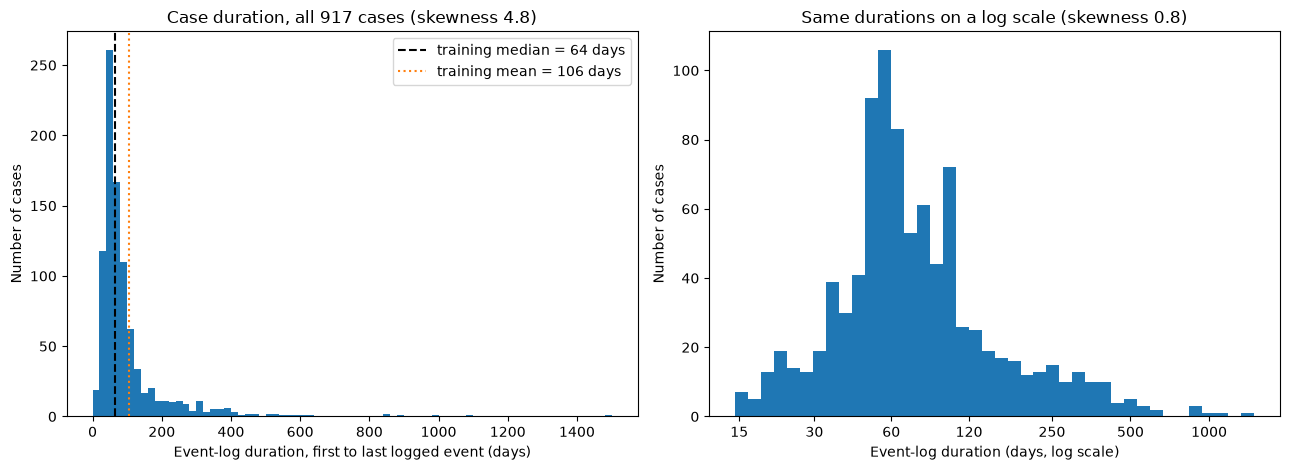

In [4]:
order = [M.TRAIN, M.VALIDATION, M.TEST]
distribution = y.groupby(split).describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).reindex(order)
distribution.loc["all cases"] = y.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])
distribution["skewness"] = list(y.groupby(split).skew().reindex(order)) + [y.skew()]
distribution["skewness of log1p(days)"] = list(np.log1p(y).groupby(split).skew().reindex(order)) + [np.log1p(y).skew()]
display(distribution.round(2))

train_y = y[split == M.TRAIN]
longest = pd.DataFrame({"start date": table["case_start"].dt.date, "event_log_days": y, "split": split,
                        "event_count_14d": table["event_count_14d"]}).loc[y.sort_values(ascending=False).index[:5]]
print(f"Training cases above 365 days: {(train_y > 365).sum()} of {len(train_y)}; "
      f"they account for {train_y[train_y > 365].sum() / train_y.sum():.0%} of all training case-days.")
print("Five longest cases in the cohort:")
display(longest.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].hist(y, bins=np.arange(0, y.max() + 20, 20), color="tab:blue")
axes[0].axvline(train_y.median(), color="black", linestyle="--", label=f"training median = {train_y.median():.0f} days")
axes[0].axvline(train_y.mean(), color="tab:orange", linestyle=":", label=f"training mean = {train_y.mean():.0f} days")
axes[0].set(title=f"Case duration, all {len(y)} cases (skewness {y.skew():.1f})",
            xlabel="Event-log duration, first to last logged event (days)", ylabel="Number of cases")
axes[0].legend()
axes[1].hist(np.log1p(y), bins=40, color="tab:blue")
ticks = [15, 30, 60, 120, 250, 500, 1000]
axes[1].set_xticks(np.log1p(ticks), [str(t) for t in ticks])
axes[1].set(title=f"Same durations on a log scale (skewness {np.log1p(y).skew():.1f})",
            xlabel="Event-log duration (days, log scale)", ylabel="Number of cases")
plt.tight_layout()
plt.savefig(figures_dir / "regression_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the distribution**

- Durations range from 14.4 to 1,486 days. In training the **median is 64 days but the mean is 106 days**: a few very
  long cases pull the mean up. Skewness is 4.9 in training (strongly right-skewed); on the log scale it falls to 0.9.
- **25 of 599 training cases (4%) last more than a year, yet they account for 23% of all training case-days.**
  These extreme cases are real cases, not errors, and **none is removed.**
- **Why ordinary Linear Regression may struggle:** least squares minimises *squared* errors, so a single 1,000-day case
  weighs as much as hundreds of typical cases. The fitted line bends towards the extremes and aims at the mean
  (106 days) rather than the typical case (64 days). A straight line can also predict impossible values (below 14 days,
  or even negative). Section 7 tests whether fitting on the log scale reduces this.

# 4. Chronological split

Same calendar-year split as the classification experiment: models learn from the past and are judged on later cases.

In [5]:
follow_up = M.follow_up_flag(table["case_start"], df[F.TIMESTAMP].max(), 365)
period = pd.DataFrame({
    "cases": split.value_counts(),
    "first start": table["case_start"].groupby(split).min().dt.date,
    "last start": table["case_start"].groupby(split).max().dt.date,
    "median days": y.groupby(split).median(),
    "mean days": y.groupby(split).mean(),
    "share > 365 days %": (y > 365).groupby(split).mean() * 100,
    "≥ 365 d follow-up %": follow_up.groupby(split).mean() * 100,
}).reindex(order)
display(period.round(1))

,cases,first start,last start,median days,mean days,share > 365 days %,≥ 365 d follow-up %
split,,,,,,,
train,599,2010-10-05,2012-12-26,64.0,105.9,4.2,100.0
validation,175,2013-01-03,2013-12-27,73.0,109.0,4.6,100.0
test,143,2014-01-05,2015-01-14,60.5,77.0,0.0,65.0


**Reading the split:** the test period looks very different from training. Its median (61 days) is close to training
(64), but **its mean is only 77 days, its longest case lasts 280 days, and not one test case exceeds a year** (4% in
training and validation). Part of this is censoring. Only 65% of test cases had a full year of follow-up before the
extract ended (July 2015), and cases still open at that point have no end date, so they are not in the cohort. The test
period therefore contains mostly the cases that finished quickly. This is the same censoring issue noted in the
classification experiment. Every model below is evaluated on the test period as it is; Section 9 adds a follow-up check.

# 5. Naive baseline

The simplest possible forecast ignores the case completely and predicts one historical number for everyone: the
**median duration of the training cases**. The training **mean** is shown as well. The median is the best single number
for MAE, the mean for RMSE. Both come from training outcomes only.

**A model is only useful if it is clearly better than this baseline on later cases.**

In [6]:
parts = {part: split == part for part in order}
def score(name, predictions):
    """predictions: dict part -> array. Returns one row per evaluated part (validation, test)."""
    return {(name, part): M.regression_metrics(y[parts[part]], predictions[part]) for part in (M.VALIDATION, M.TEST)}

baseline_median = M.constant_baseline(y[parts[M.TRAIN]], "median")
baseline_mean = M.constant_baseline(y[parts[M.TRAIN]], "mean")
predictions = {
    "baseline: training median": {p: np.full(parts[p].sum(), baseline_median) for p in order},
    "baseline: training mean": {p: np.full(parts[p].sum(), baseline_mean) for p in order},
}
results = {}
for name in predictions:
    results.update(score(name, predictions[name]))
print(f"Training median = {baseline_median:.1f} days; training mean = {baseline_mean:.1f} days "
      "(both from the 599 training cases only).")
display(pd.DataFrame(results).T[["mae", "rmse", "r2"]].astype(float).round(2))

Training median = 64.0 days; training mean = 105.9 days (both from the 599 training cases only).


mae    rmse    r2
baseline: training median validation  63.90  116.02 -0.18
                          test        30.96   50.56 -0.07
baseline: training mean   validation  71.51  106.98 -0.00
                          test        48.62   56.80 -0.35

# 6. Linear Regression

Ordinary least squares: predicted days = intercept + Σ coefficient × feature. Numeric features are standardised on the
training data; activity codes are one-hot encoded with the encoder fitted on training data only.

**The three metrics, in plain language**

- **MAE (mean absolute error):** on average, how many days the prediction is off. MAE = 30 means "typically about a
  month wrong". Lower is better.
- **RMSE (root mean squared error):** also in days, but large misses count much more (errors are squared before
  averaging). If RMSE is far above MAE, a few cases are missed very badly. Lower is better.
- **R² (coefficient of determination):** the share of the variation in duration that the model explains, compared with
  predicting the average of the evaluated period for every case. 1 = perfect, 0 = no better than that average,
  **below 0 = worse than that average.** Because the average of a *future* period is unknown when predicting, even the
  constant baseline can score below 0 out of time.
- **Mean residual:** actual − predicted, averaged. Above 0 means cases lasted longer than predicted on average; below 0
  means the model predicted too long.

In [7]:
linear = M.linear_regression_pipeline(numeric, categorical, binary).fit(X[parts[M.TRAIN]], y[parts[M.TRAIN]])
with warnings.catch_warnings():
    # A few later cases start/stop with an activity code never seen in training; it is encoded as the reference level.
    warnings.filterwarnings("ignore", message="Found unknown categories")
    predictions["linear regression"] = {p: linear.predict(X[parts[p]]) for p in order}
results.update(score("linear regression", predictions["linear regression"]))

design = linear.named_steps["preprocess"].transform(X[parts[M.TRAIN]])
print(f"Training design matrix: {design.shape[0]} cases x {design.shape[1]} columns, "
      f"rank {np.linalg.matrix_rank(np.column_stack([np.ones(len(design)), design]))} of {design.shape[1] + 1} (incl. intercept)")
for p in order:
    pred = predictions["linear regression"][p]
    print(f"{p:>10}: predictions range {pred.min():7.1f} to {pred.max():7.1f} days; "
          f"{(pred < F.SNAPSHOT_DAYS).sum()} below 14 days (impossible for a case still open at Day 14)")
display(pd.DataFrame(results).T.loc[["linear regression"], ["mae", "rmse", "r2", "mean_residual"]].astype(float).round(2))

Training design matrix: 599 cases x 40 columns, rank 39 of 41 (incl. intercept)
     train: predictions range   -66.3 to   394.1 days; 10 below 14 days (impossible for a case still open at Day 14)
validation: predictions range    13.3 to   320.2 days; 1 below 14 days (impossible for a case still open at Day 14)
      test: predictions range    82.8 to   303.6 days; 0 below 14 days (impossible for a case still open at Day 14)


mae    rmse    r2  mean_residual
linear regression validation  109.51  127.19 -0.41         -66.60
                  test        118.63  129.51 -6.02        -111.93

# 7. Log-target Linear Regression

Same predictors, same preprocessing, but the model is trained on **log1p(days)** instead of days, and every prediction is
transformed back with **expm1**, so all metrics are again **in days** and directly comparable.

Why: on the log scale the extreme multi-year cases no longer dominate the squared-error fit. A difference of 30 vs 60 days
counts as much as 300 vs 600 days. The fitted model now aims at a "typical" (roughly median) duration rather than the
mean. That usually lowers MAE but can raise RMSE, because the very long cases are predicted shorter. This is the only
variant tried; nothing is tuned.

In [8]:
log_linear = M.log_linear_regression_pipeline(numeric, categorical, binary).fit(X[parts[M.TRAIN]], y[parts[M.TRAIN]])
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Found unknown categories")
    predictions["log-target linear regression"] = {p: log_linear.predict(X[parts[p]]) for p in order}
results.update(score("log-target linear regression", predictions["log-target linear regression"]))
for p in order:
    pred = predictions["log-target linear regression"][p]
    print(f"{p:>10}: predictions range {pred.min():7.1f} to {pred.max():7.1f} days")
display(pd.DataFrame(results).T.loc[["log-target linear regression"], ["mae", "rmse", "r2", "mean_residual"]].astype(float).round(2))

     train: predictions range    23.7 to   255.8 days
validation: predictions range    41.5 to   221.7 days
      test: predictions range    39.9 to   228.3 days


mae    rmse    r2  mean_residual
log-target linear regression validation  73.47  104.27  0.05          -2.07
                             test        61.94   74.39 -1.32         -39.70

# 8. Optional non-linear comparison: Random Forest Regressor

One fixed configuration (500 trees, at least 5 cases per leaf, √features per split), mirroring the classification forest.
No hyperparameter search. A forest can capture thresholds and interactions that a straight line cannot.

In [9]:
forest = M.random_forest_regressor_pipeline(numeric, categorical, binary).fit(X[parts[M.TRAIN]], y[parts[M.TRAIN]])
predictions["random forest regressor"] = {p: forest.predict(X[parts[p]]) for p in order}
results.update(score("random forest regressor", predictions["random forest regressor"]))
display(pd.DataFrame(results).T.loc[["random forest regressor"], ["mae", "rmse", "r2", "mean_residual"]].astype(float).round(2))

mae    rmse    r2  mean_residual
random forest regressor validation  81.14  107.13 -0.00         -22.37
                        test        69.52   78.40 -1.57         -54.12

# 9. Metrics — all models side by side

Validation = 2013 (175 cases), test = Jan 2014 – Jan 2015 (143 cases). The last column is the MAE difference from the
median baseline in the same period: **negative = better than the baseline**.

In [10]:
result_table = pd.DataFrame(results).T[["cases", "mae", "rmse", "r2", "mean_residual"]].astype(float)
result_table.index.names = ["model", "split"]
result_table["MAE vs median baseline"] = [
    row["mae"] - result_table.loc[("baseline: training median", part), "mae"] for (model, part), row in result_table.iterrows()]
display(result_table.round(2))

cases     mae    rmse    r2  mean_residual  MAE vs median baseline
model                        split                                                                         
baseline: training median    validation  175.0   63.90  116.02 -0.18          45.01                    0.00
                             test        143.0   30.96   50.56 -0.07          12.93                    0.00
baseline: training mean      validation  175.0   71.51  106.98 -0.00           3.15                    7.61
                             test        143.0   48.62   56.80 -0.35         -28.93                   17.67
linear regression            validation  175.0  109.51  127.19 -0.41         -66.60                   45.61
                             test        143.0  118.63  129.51 -6.02        -111.93                   87.67
log-target linear regression validation  175.0   73.47  104.27  0.05          -2.07                    9.57
                             test        143.0   61.94   74.39 -1.32         -39.70                   30.98
random forest regressor      validation  175.0   81.14  107.13 -0.00         -22.37                   17.24
                             test        143.0   69.52   78.40 -1.57         -54.12                   38.56

In [11]:
# Is any test-period MAE improvement over the median baseline larger than chance variation? (> 0 = model better)
y_test = y[parts[M.TEST]].to_numpy()
gain = pd.DataFrame({
    name: dict(zip(["MAE gain", "95% CI low", "95% CI high"],
                   [result_table.loc[("baseline: training median", M.TEST), "mae"] - result_table.loc[(name, M.TEST), "mae"],
                    *M.bootstrap_mae_gain(y_test, predictions[name][M.TEST], predictions["baseline: training median"][M.TEST])]))
    for name in ["linear regression", "log-target linear regression", "random forest regressor"]
}).T
print("Test period: MAE(median baseline) − MAE(model), in days, with a 95% bootstrap interval:")
display(gain.round(2))

Test period: MAE(median baseline) − MAE(model), in days, with a 95% bootstrap interval:


,MAE gain,95% CI low,95% CI high
linear regression,-87.67,-99.88,-74.54
log-target linear regression,-30.98,-38.64,-23.25
random forest regressor,-38.56,-46.70,-30.05


In [12]:
# Sensitivity check (reported after the main result; changes nothing): test cases with at least a year of follow-up.
long_follow = follow_up[parts[M.TEST]].to_numpy()
sensitivity = pd.DataFrame({
    name: M.regression_metrics(y_test[long_follow], predictions[name][M.TEST][long_follow])
    for name in predictions
}).T[["cases", "mae", "rmse", "r2", "mean_residual"]].astype(float)
print(f"Test cases with ≥ 365 days of follow-up: {long_follow.sum()} of {len(long_follow)}")
display(sensitivity.round(2))

Test cases with ≥ 365 days of follow-up: 93 of 143


,cases,mae,rmse,r2,mean_residual
baseline: training median,93.0,36.49,59.61,-0.13,20.36
baseline: training mean,93.0,49.92,60.00,-0.15,-21.50
linear regression,93.0,115.66,127.16,-4.15,-105.36
log-target linear regression,93.0,63.42,75.89,-0.84,-32.01
random forest regressor,93.0,69.03,78.89,-0.98,-46.71


**Reading the results**

| | Validation 2013: MAE / RMSE / R² | Test 2014–15: MAE / RMSE / R² |
|---|---|---|
| Naive baseline (training median, 64 days) | **63.9** / 116.0 / −0.18 | **31.0** / **50.6** / −0.07 |
| Linear Regression | 109.5 / 127.2 / −0.41 | 118.6 / 129.5 / −6.02 |
| Log-target Linear Regression | 73.5 / **104.3** / **0.05** | 61.9 / 74.4 / −1.32 |
| Random Forest Regressor | 81.1 / 107.1 / −0.00 | 69.5 / 78.4 / −1.57 |

1. **No model beats the naive baseline out of time.** On the test period every model has a higher MAE than "predict
   64 days for everyone". The bootstrap intervals of the MAE difference lie entirely below 0 (e.g. log-target: −31 days,
   95% interval −39 to −23), so the gap is not chance variation. On validation, no model beats the baseline on MAE either.
   The only bright spot is the log-target model's validation RMSE (104.3 vs 107.0 for the training-mean baseline): an
   R² of 0.05, about 5% of the variation explained in 2013. That gain did not carry over to 2014.
2. **Ordinary Linear Regression is the worst model.** Out of time it is off by about **119 days on average** and
   predicts too long by 112 days on average (mean residual −112). Its test R² of −6.0 means it does far worse than simply
   predicting the test average. Within training it even predicts negative durations for some cases.
3. **The log transform clearly helps Linear Regression** (test MAE 119 → 62 days, validation 110 → 73). Taming the
   extreme durations is the right move for this target. It narrows the gap to the baseline but does not close it.
4. **The random forest** lands between the two linear models and also fails to beat the baseline.
5. **The censoring check does not rescue the models.** On the 93 test cases with at least a year of follow-up the
   ranking is identical (baseline MAE 36 days; log-target 63; forest 69; linear 116). Censoring explains part of the
   difference between periods, but not the models' failure.

**Best model out of time:** among the trained models, **log-target Linear Regression**, with the lowest MAE and RMSE on both
validation and test. It is still **worse than the naive historical median** on the test period.

# 10. Residual analysis

**Residual = actual days − predicted days.**

- **Positive residual:** the case lasted **longer** than predicted (underprediction).
- **Negative residual:** the case finished **sooner** than predicted (overprediction).

A good model has residuals centred on 0 with no pattern. The plots show the test period.

Test period residuals (actual − predicted, days):


,mean residual,median residual,share underpredicted (residual > 0) %,abs. error > 60 days %,largest underprediction,largest overprediction
baseline: training median,12.9,-3.5,47.6,11.9,216.4,-47.0
linear regression,-111.9,-126.9,7.0,87.4,116.9,-270.6
log-target linear regression,-39.7,-50.1,18.9,47.6,173.0,-176.6
random forest regressor,-54.1,-68.1,11.2,58.7,165.8,-154.4


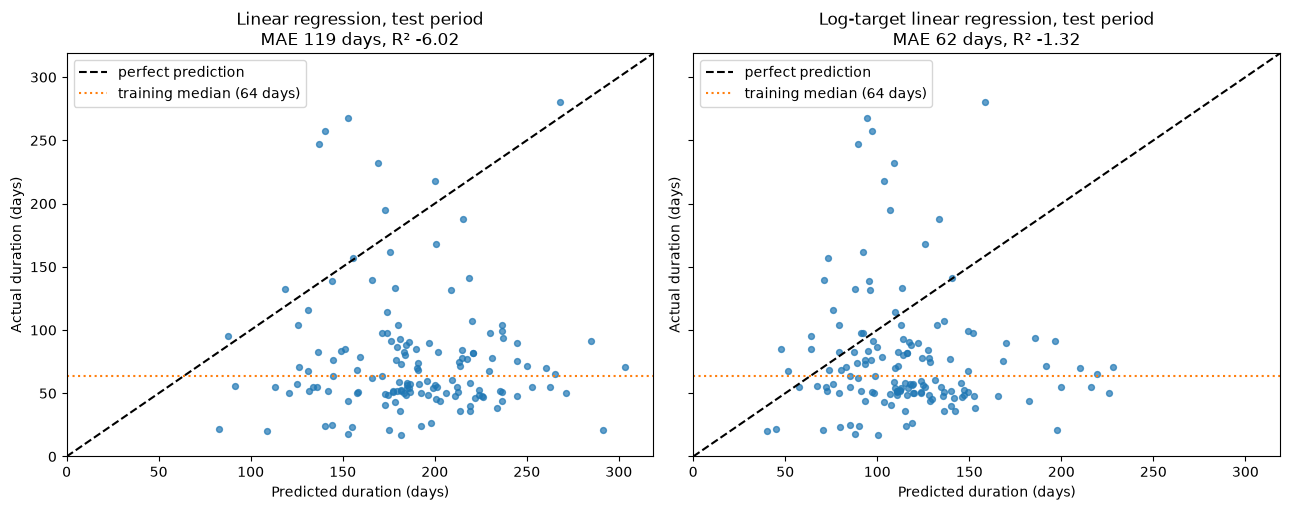

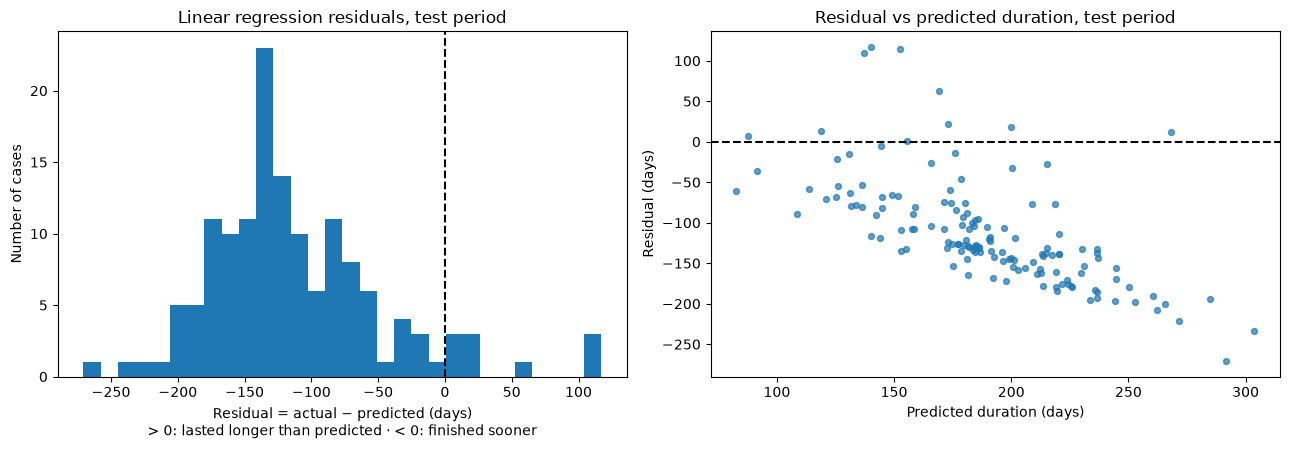

In [13]:
residual = {name: y_test - predictions[name][M.TEST] for name in predictions}
summary = pd.DataFrame({
    name: {"mean residual": r.mean(), "median residual": np.median(r),
           "share underpredicted (residual > 0) %": (r > 0).mean() * 100,
           "abs. error > 60 days %": (np.abs(r) > 60).mean() * 100,
           "largest underprediction": r.max(), "largest overprediction": r.min()}
    for name, r in residual.items() if not name.startswith("baseline: training mean")
}).T
print("Test period residuals (actual − predicted, days):")
display(summary.round(1))

limit = max(y_test.max(), max(predictions[n][M.TEST].max() for n in ("linear regression", "log-target linear regression"))) * 1.05
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharex=True, sharey=True)
for ax, name in zip(axes, ["linear regression", "log-target linear regression"]):
    ax.scatter(predictions[name][M.TEST], y_test, s=18, alpha=0.7)
    ax.plot([0, limit], [0, limit], color="black", linestyle="--", label="perfect prediction")
    ax.axhline(baseline_median, color="tab:orange", linestyle=":", label=f"training median ({baseline_median:.0f} days)")
    m = result_table.loc[(name, M.TEST)]
    ax.set(title=f"{name.capitalize()}, test period\nMAE {m['mae']:.0f} days, R² {m['r2']:.2f}",
           xlabel="Predicted duration (days)", ylabel="Actual duration (days)", xlim=(0, limit), ylim=(0, limit))
    ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(figures_dir / "regression_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

r = residual["linear regression"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].hist(r, bins=30, color="tab:blue")
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set(title="Linear regression residuals, test period",
            xlabel="Residual = actual − predicted (days)\n> 0: lasted longer than predicted · < 0: finished sooner",
            ylabel="Number of cases")
axes[1].scatter(predictions["linear regression"][M.TEST], r, s=18, alpha=0.7)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(title="Residual vs predicted duration, test period", xlabel="Predicted duration (days)",
            ylabel="Residual (days)")
plt.tight_layout()
plt.savefig(figures_dir / "regression_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the residuals (ordinary Linear Regression, test period)**

- The residuals are **not centred on 0**: mean −112 days, median −127 days. **93% of test cases finished sooner than
  predicted** (negative residual), and 87% of predictions are more than 60 days off.
- In the actual-vs-predicted plot the points lie far to the right of the diagonal. Every test prediction is between
  83 and 304 days, while most cases actually took 50–90 days. The model does not just scatter: it is **shifted**.
- The log-target model is shifted much less (mean residual −40 days) but shows the same pattern: too long for most
  cases, too short for the few long ones.
- Residual vs predicted: the higher the prediction, the more negative the residual. The model's "this will take long"
  signals are mostly wrong in the later period.

## 10.1 Three representative test cases

Chosen by a fixed rule, not hand-picked: **A** = the smallest absolute error, **B** = the largest underprediction,
**C** = the largest overprediction (ordinary Linear Regression, test period), with a few of their Day-14 features.

In [14]:
test_cases = table.index[parts[M.TEST]]
cases = pd.DataFrame({
    "actual days": y_test,
    "predicted days": predictions["linear regression"][M.TEST],
    "residual": residual["linear regression"],
}, index=test_cases)
cases["absolute error"] = cases["residual"].abs()
cases["actual remaining after Day 14"] = cases["actual days"] - F.SNAPSHOT_DAYS
cases["predicted remaining after Day 14"] = cases["predicted days"] - F.SNAPSHOT_DAYS
# Fixed selection rule (stated before looking): A = smallest absolute error,
# B = largest positive residual (underprediction), C = most negative residual (overprediction).
picked = {
    "A: relatively accurate": cases["absolute error"].idxmin(),
    "B: largest underprediction": cases["residual"].idxmax(),
    "C: largest overprediction": cases["residual"].idxmin(),
}
english = df.groupby(F.ACTIVITY)["activityNameEN"].agg(lambda s: s.value_counts().index[0])
day14 = ["event_count_14d", "unique_activity_count_14d", "unique_resource_count_14d", "resource_switch_count_14d",
         "days_since_last_event", "max_inter_event_days", "workload_cases_active_prev_30d", "latest_activity_at_snapshot"]
examples = cases.loc[list(picked.values())].join(table[day14[:-1]]).join(X[["latest_activity_at_snapshot"]])
examples["latest_activity_at_snapshot"] = examples["latest_activity_at_snapshot"].astype(str).map(
    lambda code: f"{english.get(code, code)} ({code})")
examples.index = pd.Index([f"{label} — case {case}" for label, case in picked.items()], name="example")
display(examples.drop(columns="residual").T.round(1))

example,A: relatively accurate — case 9619198,B: largest underprediction — case 10294414,C: largest overprediction — case 9612474
actual days,156.958333,257.041667,21.0
predicted days,155.664429,140.117551,291.564753
absolute error,1.293904,116.924115,270.564753
actual remaining after Day 14,142.958333,243.041667,7.0
predicted remaining after Day 14,141.664429,126.117551,277.564753
event_count_14d,9,15,11
unique_activity_count_14d,9,15,11
unique_resource_count_14d,1,1,1
resource_switch_count_14d,0,0,0
days_since_last_event,11.0,1.397222,14.0


**Reading the examples**

- **A (accurate, case 9619198):** predicted 156 days, actual 157. This is not evidence of skill. The model predicts long
  durations for nearly every test case, and this case happened to be one of the few long ones.
- **B (underprediction, case 10294414):** predicted 140 days, actual 257: 117 days longer than predicted. Its Day-14
  activity looked ordinary (15 events, all different steps, one resource, latest step "enter senddate acknowledgement").
  Nothing in the first two weeks signalled a long case.
- **C (overprediction, case 9612474):** predicted 292 days, but the case finished after 21 days, only 7 days after the
  snapshot: an error of 271 days. Overprediction is the typical failure of this model in 2014.

In "remaining time" terms (subtracting the 14 days already elapsed) the errors are identical: A 142 predicted vs 143
actual remaining days, B 126 vs 243, C 278 vs 7.

## 10.2 Why does Linear Regression predict the later periods far too long?

The residuals are not random: Linear Regression overpredicts almost every later case. The cell below breaks the change in
the **average** prediction (relative to training) into one contribution per predictor:
coefficient × (period average − training average). This is a diagnostic only; nothing is refitted.

In [15]:
def readable(name):
    group, column = name.split("__", 1)
    if group == "binary":
        code = column.removeprefix(F.ACTIVITY_FLAG_PREFIX)
        return f"reached '{english.get(code, code)}' ({code}) by Day 14"
    if group == "categorical":
        for prefix in F.CATEGORICAL_FEATURES:
            if column.startswith(prefix + "_"):
                code = column.removeprefix(prefix + "_")
                label = "other (rare) code" if code == "infrequent_sklearn" else f"'{english.get(code, code)}' ({code})"
                return f"{prefix.replace('_', ' ')} = {label}"
    return f"{column} (+1 standard deviation)"

preprocess = linear.named_steps["preprocess"]
names = preprocess.get_feature_names_out()
coefficients = M.linear_regression_coefficients(linear)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Found unknown categories")
    encoded_mean = {p: pd.DataFrame(preprocess.transform(X[parts[p]]), columns=names).mean() for p in order}

# Contribution of each predictor to the change in the AVERAGE prediction relative to the training period:
# coefficient × (period mean − training mean) on the preprocessed scale. The contributions add up exactly.
shift = pd.DataFrame({p: coefficients * (encoded_mean[p] - encoded_mean[M.TRAIN]) for p in (M.VALIDATION, M.TEST)})
print("Average linear-regression prediction: " + ", ".join(
    f"{p} {predictions['linear regression'][p].mean():.0f} days (actual mean {y[parts[p]].mean():.0f})" for p in order))
print("Shift of the average prediction vs training: " + ", ".join(f"{p} {shift[p].sum():+.0f} days" for p in shift))
top = shift[M.TEST].abs().sort_values(ascending=False).index[:6]
drivers = pd.DataFrame({
    "feature": [readable(n) for n in top],
    "coefficient (days)": coefficients[top].to_numpy(),
    **{f"mean in {p}": [encoded_mean[p][n] for n in top] for p in order},
    "contribution to test shift (days)": shift.loc[top, M.TEST].to_numpy(),
}).set_index("feature")
print("Largest contributors (for activity flags, 'mean' = share of cases that reached the step by Day 14):")
display(drivers.round(2))

Average linear-regression prediction: train 106 days (actual mean 106), validation 176 days (actual mean 109), test 189 days (actual mean 77)
Shift of the average prediction vs training: validation +70 days, test +83 days
Largest contributors (for activity flags, 'mean' = share of cases that reached the step by Day 14):


,coefficient (days),mean in train,mean in validation,mean in test,contribution to test shift (days)
feature,,,,,
reached 'forward to the competent authority' (02_DRZ_010) by Day 14,138.93,0.43,0.96,0.95,71.83
reached 'send procedure confirmation' (01_HOOFD_065_1) by Day 14,-111.14,0.59,0.00,0.01,64.35
reached 'regular procedure without MER' (04_BPT_005) by Day 14,-99.82,0.43,0.94,0.95,-52.44
reached 'enter senddate procedure confirmation' (01_HOOFD_065_2) by Day 14,42.15,0.66,0.00,0.01,-27.71
workload_cases_active_prev_30d (+1 standard deviation),-18.61,-0.00,-1.32,-1.09,20.25
events_per_active_day (+1 standard deviation),18.91,-0.00,0.59,1.03,19.46


**Reading the diagnostic: the early process changed between periods.**

- The average Linear Regression prediction rises from **106 days in training to 176 in 2013 and 189 in 2014–15**,
  while the actual averages are 109 and 77. Changes in the predictors alone push the average prediction **up by
  70 days (validation) and 83 days (test)**.
- The way cases looked at Day 14 changed after 2012:
  - **"forward to the competent authority" (02_DRZ_010)** was reached by Day 14 in **43% of training cases but about 95%
    of later cases**. In 2010–2012 it was associated with longer cases (+139 days). In later years it became routine,
    and this flag alone adds about +72 days to the average test prediction.
  - **"send procedure confirmation" (01_HOOFD_065_1)** was reached by Day 14 in 59% of training cases and in almost none
    later (≈ 1%). Its *absence*, associated with longer cases in training, adds another +64 days.
  - "regular procedure without MER" (04_BPT_005) also rose from 43% to 95%, pulling predictions down (−52 days) and
    partly offsetting the first two. Lower recent workload and more events per active day add about +20 days each.
- **This is the regression view of the classification finding.** The early process, or the way it was recorded,
  changed after 2012, so patterns learned from 2010–2012 did not transfer. A linear model carries such shifts directly
  into its day estimates. The log-target model and the forest are less sensitive, but they learned from the same history.

# 11. Interpretation — Linear Regression coefficients

Coefficients are read on the preprocessed scale. For a numeric feature: the change in predicted days for **one standard
deviation** more of that feature. For an activity flag or category: the change in predicted days when it is present,
compared with the reference. Everything else is held fixed.

These are **associations within this model, not causes**. Several Day-14 counts are strongly correlated with each other,
so individual coefficients can be unstable: they share credit between related features, and their signs can flip.
Read them as "associated with longer / shorter predicted duration", and only in the light of the out-of-time
performance in Section 9.

In [16]:
# Remaining exact dependencies in the TRAINING design. They make some coefficients non-identifiable: least squares
# then splits the credit between the dependent columns. Predictions are unaffected.
train_design = pd.DataFrame(design, columns=names)
identical = [(a, b) for i, a in enumerate(names) for b in names[i + 1:] if train_design[a].equals(train_design[b])]
print("Columns identical in every training case:", [(readable(a), readable(b)) for a, b in identical] or "none")
_, singular, vt = np.linalg.svd(np.column_stack([np.ones(len(design)), design]), full_matrices=False)
for vector in vt[singular < 1e-8 * singular[0]]:
    print("Exact linear dependency among:", [readable(n) for n, w in zip(["intercept", *names], vector) if abs(w) > 0.01])
print()

coef_table = pd.DataFrame({"feature": [readable(n) for n in coefficients.index], "days": coefficients.to_numpy()})
coef_table = coef_table.reindex(coef_table["days"].abs().sort_values(ascending=False).index)
print(f"Intercept: {linear.named_steps['model'].intercept_:.1f} days. "
      "Each coefficient = change in PREDICTED duration (days), holding the other predictors fixed.")
print("\nStrongest associations with LONGER predicted duration:")
display(coef_table[coef_table["days"] > 0].head(8).round(1).set_index("feature"))
print("Strongest associations with SHORTER predicted duration:")
display(coef_table[coef_table["days"] < 0].head(8).round(1).set_index("feature"))

Columns identical in every training case: [("reached 'phase application received' (01_HOOFD_015) by Day 14", "reached 'send confirmation receipt' (01_HOOFD_020) by Day 14")]
Exact linear dependency among: ['event_count_14d (+1 standard deviation)', 'unique_activity_count_14d (+1 standard deviation)', 'repeated_activity_count_14d (+1 standard deviation)']
Exact linear dependency among: ["reached 'phase application received' (01_HOOFD_015) by Day 14", "reached 'send confirmation receipt' (01_HOOFD_020) by Day 14"]

Intercept: 109.5 days. Each coefficient = change in PREDICTED duration (days), holding the other predictors fixed.

Strongest associations with LONGER predicted duration:


,days
feature,
first activity = other (rare) code,160.7
reached 'forward to the competent authority' (02_DRZ_010) by Day 14,138.9
reached 'forward to the competent authority' (01_HOOFD_040) by Day 14,63.4
reached 'enter senddate acknowledgement' (01_HOOFD_030_2) by Day 14,58.6
reached 'enter senddate procedure confirmation' (01_HOOFD_065_2) by Day 14,42.2
reached 'phase application received' (01_HOOFD_015) by Day 14,30.8
reached 'send confirmation receipt' (01_HOOFD_020) by Day 14,30.8
events_per_active_day (+1 standard deviation),18.9


Strongest associations with SHORTER predicted duration:


,days
feature,
latest activity at snapshot = 'regular procedure without MER' (01_HOOFD_060),-121.5
reached 'send procedure confirmation' (01_HOOFD_065_1) by Day 14,-111.1
reached 'regular procedure without MER' (04_BPT_005) by Day 14,-99.8
reached 'send confirmation receipt' (01_HOOFD_030_1) by Day 14,-75.6
latest activity at snapshot = 'send confirmation receipt' (01_HOOFD_030_1),-69.4
reached 'registrer date of publishing received request' (01_HOOFD_100) by Day 14,-50.8
latest activity at snapshot = 'registrer date of publishing received request' (01_HOOFD_100),-44.0
reached 'inform BAG administrator' (01_HOOFD_050) by Day 14,-30.5


**Reading the coefficients, carefully**

- Steps such as "forward to the competent authority" (02_DRZ_010, 01_HOOFD_040) reached by Day 14, or a rare first
  activity, are **associated with longer predicted duration** in the training period.
- Reaching "send procedure confirmation" (01_HOOFD_065_1) or "regular procedure without MER" (04_BPT_005) by Day 14,
  or having "regular procedure without MER" (01_HOOFD_060) as the latest step, is **associated with shorter predicted
  duration**.
- **Several coefficients are not individually meaningful.** Two flags (01_HOOFD_015 and 01_HOOFD_020) are identical in
  every training case, so their identical +30.8 days is one shared effect split in half. In training, the event count also
  equals unique activities + repeated activities exactly, so those three coefficients cannot be separated either.
  Coefficients of 100+ days for a single activity flag are a sign of strongly correlated predictors offsetting each
  other, not of real 100-day effects.
- Section 10.2 shows that the strongest associations (02_DRZ_010 and 01_HOOFD_065_1 above all) were **specific to
  2010–2012** and did not hold later. **None of these coefficients should be read as a cause of long or short cases**,
  nor as a reliable pattern for SPAR.

# 12. Regression interpretation for SPAR

**Classification asks:** *"Will this case become long-running?"* (yes/no, relative to a historical threshold).
**Regression asks:** *"Approximately how long might this case last?"* (a number of days).

A regression output is easier to act on. A future SPAR interface could, in principle, show for an open case at Day 14:

> Estimated total duration: **~120 days**, or equivalently, estimated remaining duration after Day 14: **~106 days**

**but only if such a model has been trained and validated on real SPAR/Montenegro data and shown to beat a simple
historical estimate out of time.** This experiment shows why that condition matters. On the BPI data, the Linear
Regression estimate for 2014 cases was **off by about 119 days on average** and almost always too long. The honest
number to display would have been the **historical median (≈ 64 days)**, which was off by about 31 days. An estimate in
days *looks* precise, and that is exactly why it must not be shown before it is validated.

Before any duration estimate is shown to staff, it should be:

- validated on SPAR data, chronologically, against a naive historical baseline;
- shown with an uncertainty range, not a single number;
- monitored over time and re-trained when procedures or recording practices change, as they did in this data
  (Section 10.2);
- used for decision support only: it informs where staff may look. It is never used to rank or evaluate employees,
  and it does not replace a legal deadline.

The richer process data recommended in the classification evaluation (workflow states, request type, responsible unit,
waiting on another actor, structured hold reasons, due-date changes, precise timestamps) would be needed for regression too.

## 12.1 Did regression provide more useful information than classification?

| | Classification (locked, primary) | Regression (this extension) |
|---|---|---|
| Question | long-running yes/no (> 104.6 days) | duration in days |
| Validation 2013 | weak signal (RF ROC-AUC 0.57) | no MAE gain over baseline; log-target R² 0.05 |
| Test 2014–15 | chance level (ROC-AUC 0.49, PR-AUC 0.14 = prevalence) | every model worse than the training median |
| What it adds | high recall hides a "flag everyone" model | errors in days and their direction: systematic overprediction |

**Predictive value: no.** Judged by out-of-time performance, not appearance, regression did **not** provide more useful
predictions. Both experiments reach the same conclusion: Day-14 information from 2010–2012 does not generalise to
later cases. If anything, regression fails more clearly, because it loses to a constant.

**Diagnostic value: some.** Errors in days make the failure concrete ("off by about four months on average"). The
residual direction exposes the mechanism: the early process changed after 2012, and the test cohort contains mostly
short, already-closed cases. This supports the existing data-design lesson for SPAR; it does not change it.

**Recommendation for the presentation: B, one backup slide.** The main story already makes this point with the
classification result, and an 8–10 minute talk has no room for a second negative result. A backup slide answers the
obvious question "Did you also try predicting the number of days?". Suggested content: the test table (baseline MAE
31 days vs 62–119 for the models), the actual-vs-predicted figure, and one line: "The log transform helped, but no
model beat the historical median: the early process changed after 2012."

# 13. Limitations

- **Censoring of the later periods:** only closed cases have a duration. The test cohort (2014 – Jan 2015) contains no
  case longer than 280 days, and 35% of its cases had less than a year of follow-up, so the test target is biased
  towards short cases. The follow-up check (Section 9) does not change the ranking.
- **Process change over time:** early activity patterns shifted after 2012 (Section 10.2). Any model trained on older
  cases inherits this problem; it is a property of the data, not only of the model.
- **Duration = first to last *logged* event,** not a legal or administrative processing time. Timestamps are mostly
  date-level.
- **Linear model limits:** least squares is sensitive to extreme cases, can predict impossible values (below 14 days),
  and has unstable coefficients when predictors are correlated (Section 11). The log-target model predicts roughly a
  *typical* (median-like) duration. No bias correction was applied, so its predicted mean is lower by design.
- **One variant per model, no tuning:** results could differ with other features or settings, but searching for them
  after seeing these results would no longer be an honest out-of-time test.
- **No prediction intervals:** a usable duration estimate would need an uncertainty range.
- **Small test set** (143 cases) from **one Dutch municipality, 2010–2015**: external proof-of-concept data, not SPAR
  or Montenegro data.

# 14. Final conclusion

**Research question:** *Can information available 14 days after an administrative case starts predict how long the case
will ultimately last?*

**Answer: not in this dataset.** The regression used the same 917 cases, Day-14 features and chronological split as the
locked classification experiment. No model beat the naive forecast "every case takes the training median of 64 days"
on later cases. Ordinary Linear Regression was off by about 119 days on average for 2014 cases (baseline: 31) and
overpredicted almost every case. Training on log-duration roughly halved that error (62 days) and gave the best
trained model, but it still lost clearly to the baseline. A fixed random forest did no better (70 days).

The diagnostics point the same way as the classification evaluation. The early process changed after 2012, so patterns
learned from older cases did not transfer, and the later cohort is limited to cases that had already closed. For SPAR,
the lesson is unchanged and reinforced: **a duration estimate is only as good as the process data behind it, and it must
beat a simple historical baseline out of time before anyone relies on it.**

This extension does not change the primary classification result or conclusion. The locked experiment was re-run at the
start of this notebook and reproduced exactly.

In [17]:
assert raw_sha256() == recorded_hashes["BPIC15_1.xes"], "raw XES changed during this notebook"
print("Raw XES checksum unchanged:", raw_sha256())

Raw XES checksum unchanged: 7591f70d4a4d536ead76a56c2fa493fbe22bf2ec7e06c8ddd29da79bd666e516
